**Aim:** anlysis of scRNA-seq data

**Tools**: 
1. Preprocessing: [`scanpy`](https://scanpy.readthedocs.io/en/stable/)
2. Normalization/denoising/imputation of expression: [`scvi`](https://docs.scvi-tools.org/en/stable/user_guide/models/scvi.html)

In [1]:
import matplotlib.pyplot as plt
import scanpy as sc
import scvi
import scez

scanpy==1.9.6 anndata==0.10.7 umap==0.5.5 numpy==1.26.4 scipy==1.13.0 pandas==1.5.3 scikit-learn==1.4.2 statsmodels==0.14.2 igraph==0.11.5 pynndescent==0.5.12


# 1. Preprocessing

## Run `scVI`

### Prepare data 

In [2]:
results_file = 'preprocessing/adata-cleaned-v3.h5ad.gz'

adata0 = sc.read_h5ad(results_file)

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Exclude female!?

In [4]:
adata0 = adata0[~adata0.obs.cond.str.contains('female')].copy()

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


___
https://docs.scvi-tools.org/

In [5]:
adata = adata0.copy()

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/anndata/_core/anndata.py:1820: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [6]:
adata.layers["counts"] = adata.X.copy() # preserve counts
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata # freeze the state in `.raw`

In [7]:
adata.layers["counts_norm"] = adata.X.copy()

___

In [8]:
adata.to_df(layer='counts').max().max()

19657.0

In [9]:
adata.to_df(layer='counts_norm').max().max()

9.046857

https://docs.scvi-tools.org/en/stable/tutorials/notebooks/api_overview.html#Loading-and-preparing-data
> Finally, we perform feature selection, to reduce the number of features (genes in this case) used as input to the scvi-tools model. For best practices of how/when to perform feature selection, please refer to the model-specific tutorial. For scVI, we recommend anywhere from 1,000 to 10,000 HVGs, but it will be context-dependent.


In [10]:
adata.var_names_make_unique()

In [11]:
sc.pp.highly_variable_genes(
    adata, #min_mean=0.0125, max_mean=3, min_disp=0.5,
    n_top_genes=10000,
    subset=True,
    # layer="counts",
    flavor="cell_ranger",
    batch_key="batch"
)

#### Run `scvi`

In [17]:
# scvi.model.SCVI.setup_anndata(
scvi.data.setup_anndata(
    adata,
    layer="counts",
    batch_key="batch",
    categorical_covariate_keys=["batch"], # , "group"
    # continuous_covariate_keys=["percent_mito", "percent_ribo"]
)

INFO     Using batches from adata.obs["batch"]                                                                     
INFO     No label_key inputted, assuming all cells have same label                                                 
INFO     Using data from adata.layers["counts"]                                                                    
INFO     Computing library size prior per batch                                                                    
INFO     Successfully registered anndata object containing 23801 cells, 10000 vars, 12 batches, 1 labels, and 0    
         proteins. Also registered 1 extra categorical covariates and 0 extra continuous covariates.               
INFO     Please do not further modify adata until model is trained.                                                


In [18]:
model = scvi.model.SCVI(adata)

In [97]:
model

SCVI Model with the following params: 
n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, gene_likelihood: zinb, 
latent_distribution: normal
Training status: Trained

To print summary of associated AnnData, use: scvi.data.view_anndata_setup(model.adata)

In [26]:
model.train(n_epochs=400,train_size=0.8,test_size=0.1)

# test_size (Union[int, float, None]) – The test size, a float between 0 and 1 representing proportion of dataset to use for testing to use 
# Default: None, which is equivalent to data not in the train set. 
# If train_size and test_size do not add to 1 then the remaining samples are added to a validation_set.

INFO     Training for 400 epochs                                                                                   
INFO     KL warmup for 400 epochs                                                                                  
Training...: 100%|██████████| 400/400 [31:26<00:00,  4.72s/it]
INFO     Training time:  1890 s. / 400 epochs                                                                      


In [27]:
model.save("preprocessing/scvi_model_v3/")

___

Load pre-trained model:

In [ ]:
model = scvi.model.SCVI.load(
    # "preprocessing/scvi_model_v1/", adata=adata, use_gpu=False
    # "preprocessing/scvi_model_v2/", adata=adata, use_gpu=False
    "preprocessing/scvi_model_v3/", adata=adata, use_gpu=False
)

### Obtaining model outputs


In [28]:
latent = model.get_latent_representation()

It’s often useful to store the outputs of scvi-tools back into the original anndata, as it permits interoperability with Scanpy.


In [29]:
adata.obsm["X_scVI"] = latent

In [30]:
adata.layers["scvi_normalized"] = model.get_normalized_expression(
    library_size=10e4
)

In [31]:
results_file = 'preprocessing/adata-denoised-v3.h5ad.gz'

adata.write_h5ad(results_file)

### Plot training epochs ...

In [41]:
scvi.data.view_anndata_setup(model.adata)

Anndata setup with scvi-tools version 0.8.1.

              Data Summary              
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃             Data             ┃ Count ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│            Cells             │ 23801 │
│             Vars             │ 10000 │
│            Labels            │   1   │
│           Batches            │  12   │
│           Proteins           │   0   │
│ Extra Categorical Covariates │   1   │
│ Extra Continuous Covariates  │   0   │
└──────────────────────────────┴───────┘

                    SCVI Data Registry                    
┏━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃     Data      ┃          scvi-tools Location           ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       X       │         adata.layers['counts']         │
│ batch_indices │        adata.obs['_scvi_batch']        │
│ local_l_mean  │    adata.obs['_scvi_local_l_mean']     │
│  local_l_var  │     adata.obs['_scvi_local_l_var']     │
│    labels     │       adata.obs['_scvi_labels']        │
│   cat_covs    │ adata.obsm['_scvi_extra_categoricals'] │
└───────────────┴────────────────────────────────────────┘

                        Label Categories                        
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃      Source Location      ┃ Categories ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['_scvi_labels'] │     0      │          0          │
└───────────────────────────┴────────────┴─────────────────────┘

                        Batch Categories                        
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃  Source Location   ┃    Categories     ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['batch'] │ MDMA_acute_male_1 │          0          │
│                    │ MDMA_acute_male_2 │          1          │
│                    │ MDMA_acute_male_3 │          2          │
│                    │    MDMA_male_1    │          3          │
│                    │    MDMA_male_2    │          4          │
│                    │    MDMA_male_3    │          5          │
│                    │    Meth_male_1    │          6          │
│                    │    Meth_male_2    │          7          │
│                    │    Meth_male_3    │          8          │
│                    │   Saline_male_1   │          9          │
│                    │   Saline_male_2   │         10          │
│                    │   Saline_male_3   │         11          │
└────────────────────┴───────────────────┴─────────────────────┘

                  Extra Categorical Variables                   
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃  Source Location   ┃    Categories     ┃ scvi-tools Encoding ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ adata.obs['batch'] │ MDMA_acute_male_1 │          0          │
│                    │ MDMA_acute_male_2 │          1          │
│                    │ MDMA_acute_male_3 │          2          │
│                    │    MDMA_male_1    │          3          │
│                    │    MDMA_male_2    │          4          │
│                    │    MDMA_male_3    │          5          │
│                    │    Meth_male_1    │          6          │
│                    │    Meth_male_2    │          7          │
│                    │    Meth_male_3    │          8          │
│                    │   Saline_male_1   │          9          │
│                    │   Saline_male_2   │         10          │
│                    │   Saline_male_3   │         11          │
│                    │                   │                     │
└────────────────────┴───────────────────┴─────────────────────┘

In [47]:
# fig, ax = plt.subplots(nrows=1, ncols=1,figsize=(2,2),dpi=150)

# ax.plot(model.history["elbo_train"], label="elbo_train")
# ax.plot(model.history["train_loss_epoch"], label="train_loss_epoch")
# # axes[i].set_ylim(9000, 15000)
# ax.legend()

# fig.tight_layout()
# # fig.savefig('figures/totalVI_training.pdf')

## Explore

In [80]:
results_file = 'preprocessing/adata-denoised-v3.h5ad.gz'

adata = sc.read_h5ad(results_file)

raw counts

In [81]:
# # run PCA then generate UMAP plots
# sc.tl.pca(adata)
# sc.pp.neighbors(adata, n_pcs=30, n_neighbors=20)
# sc.tl.umap(adata, min_dist=0.1)

In [82]:
# sc.pl.umap(
#     adata,
#     color=["batch"],
#     frameon=False,alpha=0.5,size=10
# )

scvi counts

In [83]:
# use scVI latent space for UMAP generation
sc.pp.neighbors(adata, use_rep="X_scVI")
sc.tl.umap(adata, min_dist=0.3)

In [84]:
# neighbors were already computed using scVI
sc.tl.leiden(adata, key_added="leiden_scVI", resolution=1)

### UMAP after denoising 

In [ ]:
import numpy as np

In [ ]:
# Randomly order cells by making a random index and subsetting AnnData based on it
# Set a random seed to ensure that the cell ordering will be reproducible
np.random.seed(0)
random_indices = np.random.permutation(list(range(adata.shape[0])))

In [94]:
adata.layers['scaled'] = sc.pp.scale(adata, max_value=10, copy=True).X

/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:371: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:381: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:371: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/data_gilbert/home/aarab/anaconda3/envs/mamba/envs/scez/lib/python3.9

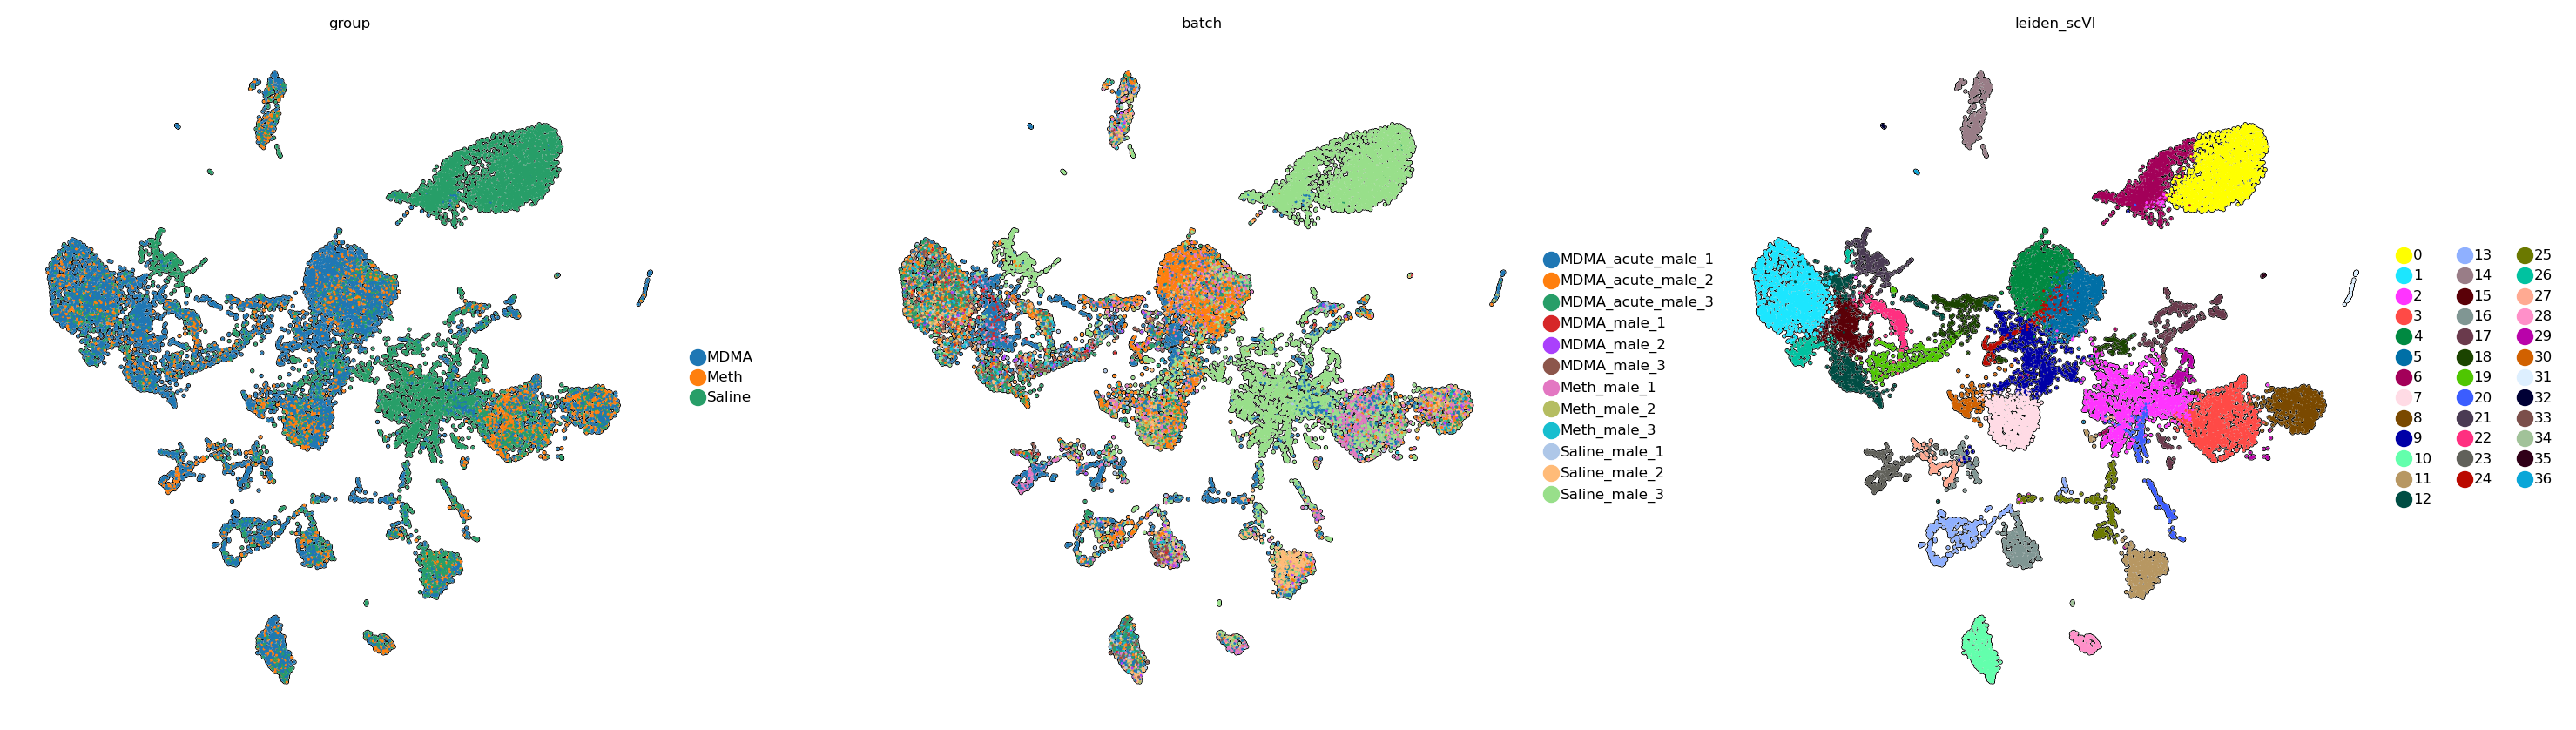

In [93]:
sc.pl.umap(
    adata[random_indices],
    color=[
        'group',
        "batch",
        'leiden_scVI',
    ],
    layer='scaled',
    cmap='Reds',
    frameon=False,
    alpha=1,
    size=5,
    add_outline=0.1
)

# 

In [95]:
results_file = 'preprocessing/adata-denoised-clustered-v3.h5ad.gz'

adata.write_h5ad(results_file)

In [96]:
ls -lh preprocessing/adata-denoised-clustered*

-rw-rw-r--. 1 aarab aarab 4.3G Aug 12  2022 preprocessing/adata-denoised-clustered.h5ad.gz
-rw-rw-r--. 1 aarab aarab 5.1G Apr  3  2023 preprocessing/adata-denoised-clustered-v2.1.h5ad.gz
-rw-rw-r--. 1 aarab aarab 4.3G Aug 26  2022 preprocessing/adata-denoised-clustered-v2.h5ad.gz
-rw-rw-r--. 1 aarab aarab 7.4G May 19  2024 preprocessing/adata-denoised-clustered-v3.h5ad.gz


# 

In [88]:
!date

Sun May 19 19:35:45 PDT 2024


In [89]:
%reload_ext watermark
%watermark
%watermark --iversions

Last updated: 2024-05-19T19:35:46.123051-07:00

Python implementation: CPython
Python version       : 3.9.19
IPython version      : 8.18.1

Compiler    : GCC 12.3.0
OS          : Linux
Release     : 3.10.0-957.27.2.el7.x86_64
Machine     : x86_64
Processor   : x86_64
CPU cores   : 64
Architecture: 64bit

scanpy    : 1.9.6
scez      : 0.0.5
matplotlib: 3.6.3
scvi      : 0.8.1

